# Data Loading

In [1]:
import pandas as pd

# Memuat dataset e-commerce
train = pd.read_csv("ecommerce_sales_customer_analytics_150k.csv")
train.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


# Data Cleaning dan Transformation

In [2]:
# Menampilkan ringkasan informasi dari dataset
train.info()

# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
print(missing_values[missing_values > 0])

# Memisahkan kolom berdasarkan jumlah missing value
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

# Mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

# Cek kembali missing values
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

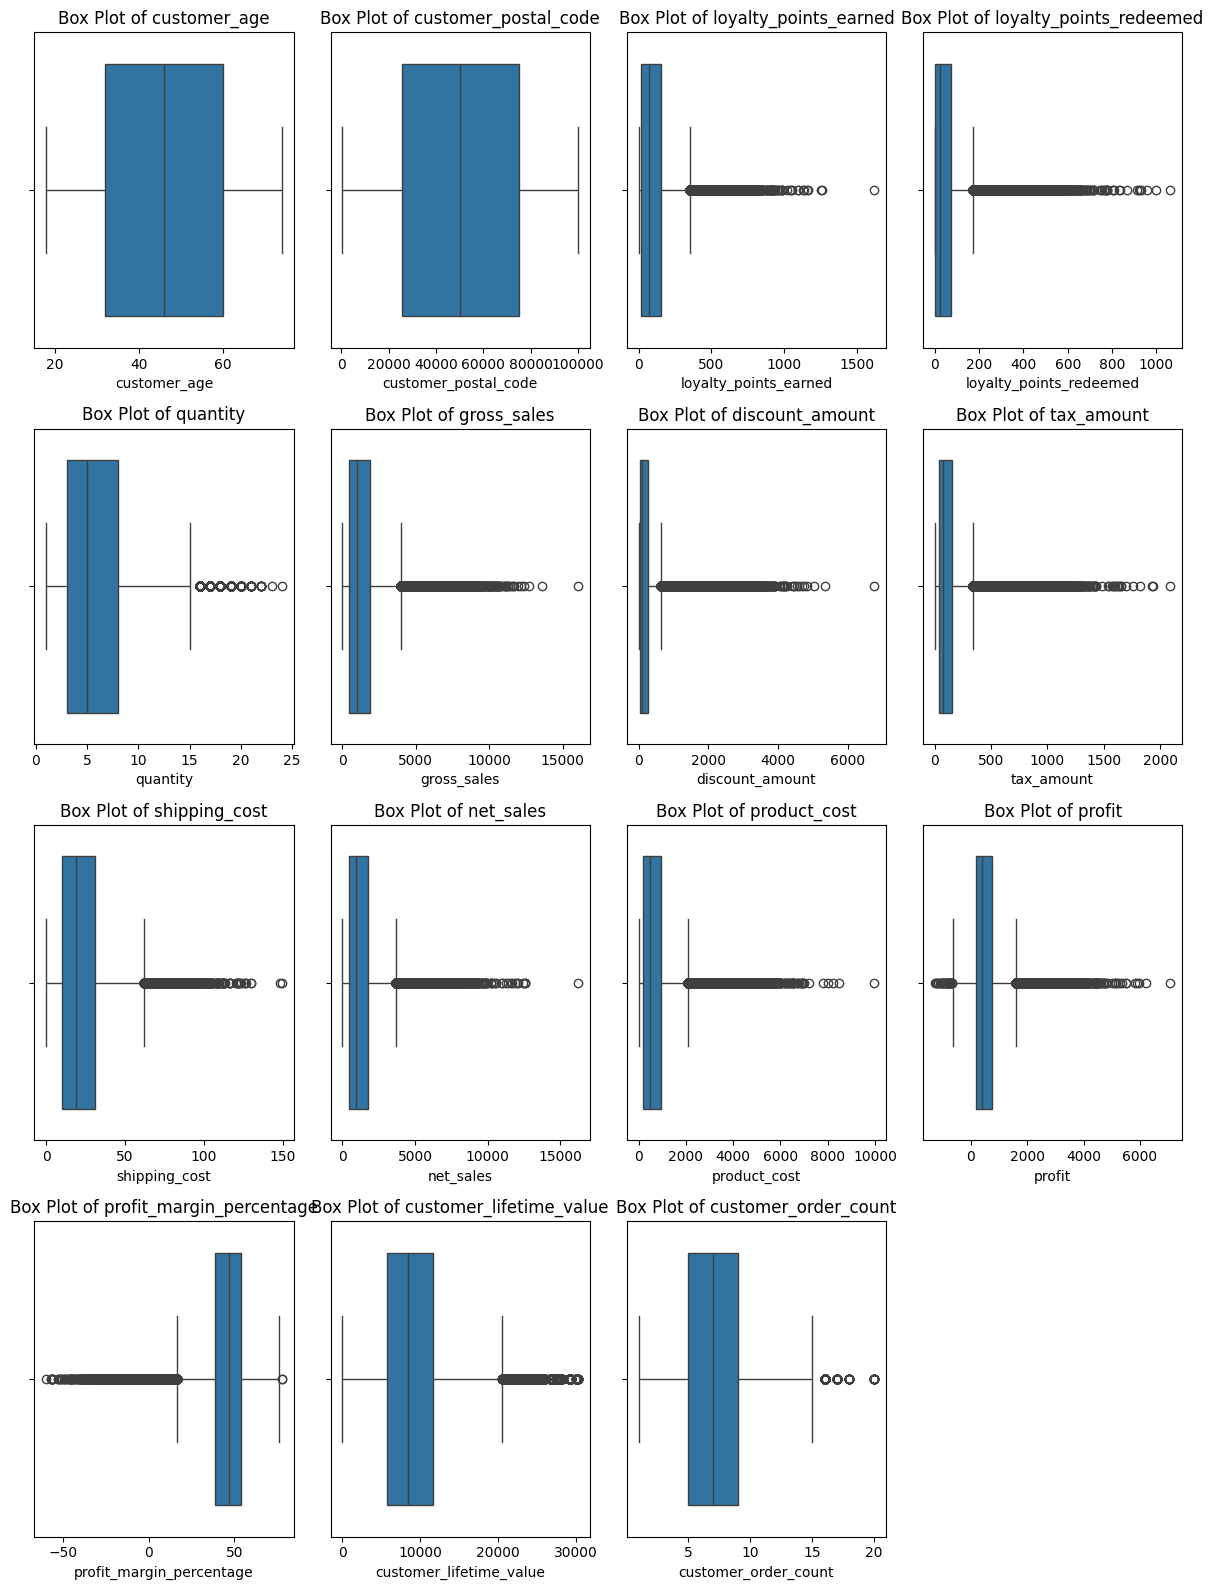

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Tentukan jumlah kolom per baris
n_cols = 4
n_features = len(numeric_features)
n_rows = math.ceil(n_features / n_cols)

# Buat subplot dengan grid n_rows x n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))

# Ubah axes menjadi 1D array agar mudah di-loop (jika bentuknya matrix 2D)
axes = axes.flatten()

# Loop untuk menampilkan boxplot
for i, feature in enumerate(numeric_features):
    sns.boxplot(x=df[feature], ax=axes[i])
    axes[i].set_title(f'Box Plot of {feature}')

# Hapus sisa kotak subplot yang kosong jika jumlah fitur ganjil
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [4]:
# Identifikasi dan hapus outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk menyimpan baris tanpa outliers ekstrim
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

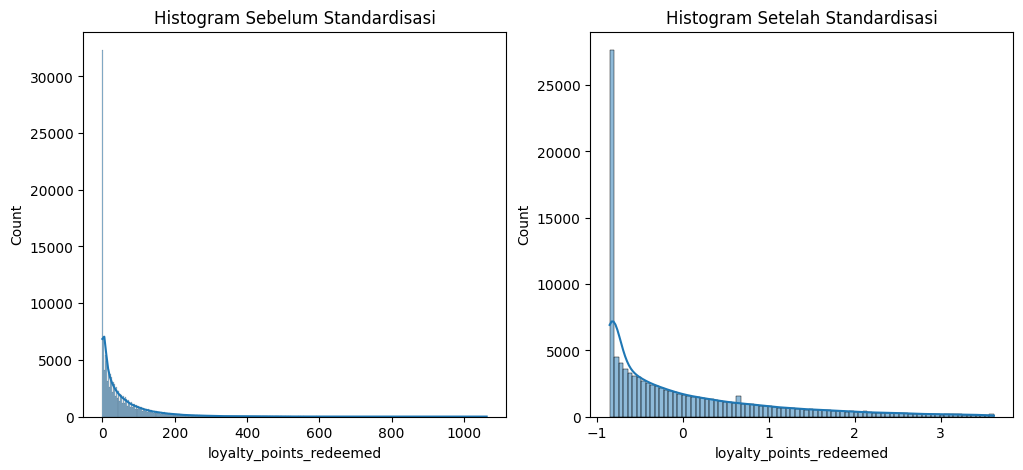

In [5]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# Menampilkan Histogram Sebelum & Sesudah Standardisasi (Mengambil contoh kolom ke-3)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

In [6]:
# Mengidentifikasi & Menghapus baris duplikat
duplicates = df.duplicated()
print("Jumlah Baris duplikat:", duplicates.sum())

df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikat:\n", df.head())

Jumlah Baris duplikat: 0
DataFrame setelah menghapus duplikat:
    customer_age  customer_postal_code  loyalty_points_earned  \
0      0.557129              1.254409               0.366000   
2      1.407549             -1.056670              -0.359124   
3      1.164572              0.564693              -0.238270   
7     -0.171802             -1.697818               2.556478   
8     -1.447432             -1.004952              -0.087203   

   loyalty_points_redeemed  quantity  gross_sales  discount_amount  \
0                 0.284206  0.085528     0.662633         2.594817   
2                -0.440193  0.085528    -0.573955        -0.175032   
3                -0.595422 -0.996371    -0.541358        -0.494963   
7                 2.276305  1.167427     2.406063         1.304322   
8                -0.698907 -0.996371    -0.498493        -0.652526   

   tax_amount  shipping_cost  net_sales  ...  customer_state  \
0   -0.266141      -0.581290   0.093361  ...           Texas   
2 

In [7]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding untuk kolom kategorikal
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
category_features = df.select_dtypes(include=['object']).columns

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col].astype(str))

df_lencoder.head()

,customer_age,customer_postal_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,...,customer_state,customer_country,region,payment_method,payment_status,currency,shipping_method,warehouse,delivery_status,marketing_channel
0,0.557129,1.254409,0.366000,0.284206,0.085528,0.662633,2.594817,-0.266141,-0.581290,0.093361,...,33,6,3,5,1,6,3,2,3,1
2,1.407549,-1.056670,-0.359124,-0.440193,0.085528,-0.573955,-0.175032,-0.722579,-0.507041,-0.641681,...,20,6,1,2,1,6,1,14,3,9
3,1.164572,0.564693,-0.238270,-0.595422,-0.996371,-0.541358,-0.494963,-0.655456,0.060749,-0.521236,...,21,6,3,4,1,6,1,9,3,2
7,-0.171802,-1.697818,2.556478,2.276305,1.167427,2.406063,1.304322,1.106381,0.168484,2.324729,...,20,6,1,6,1,6,3,2,3,1
8,-1.447432,-1.004952,-0.087203,-0.698907,-0.996371,-0.498493,-0.652526,-0.129852,0.604518,-0.376678,...,27,1,1,3,1,2,2,17,3,7


# EDA & ExDA

In [8]:
# Mengecek ulang missing values dalam persentase
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

print(missing_data[missing_data['Missing Values'] > 0])

Empty DataFrame
Columns: [Missing Values, Percentage]
Index: []


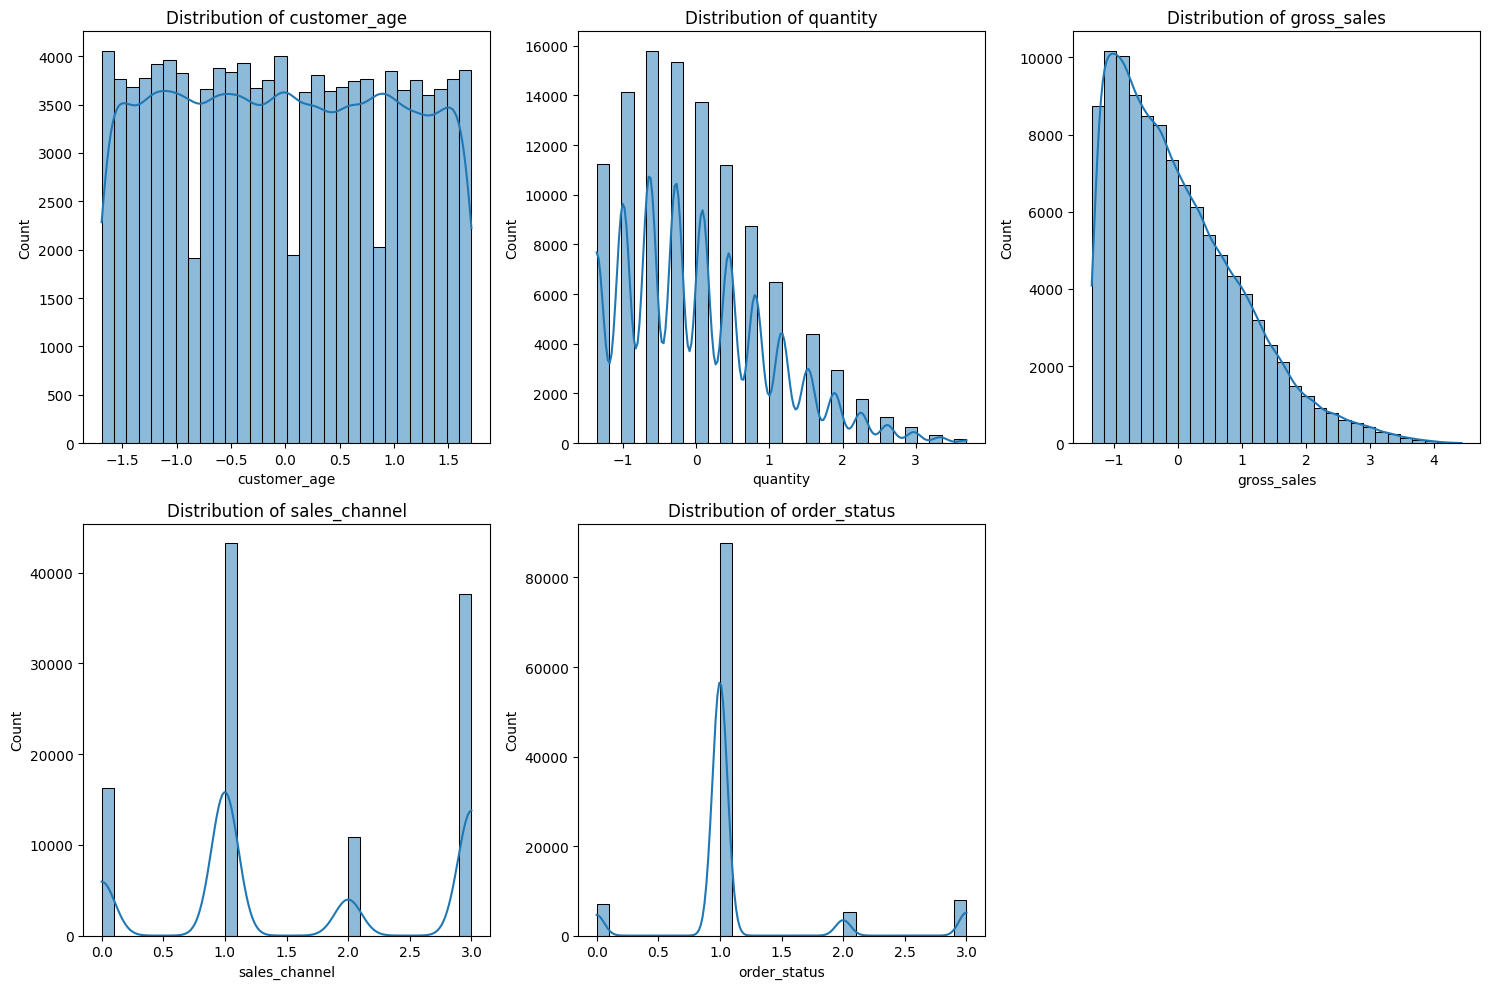

In [9]:
# Visualisasi distribusi data untuk kolom-kolom utama e-commerce
# Mengganti OverallQual dkk dengan fitur yang relevan di dataset e-commerce
columns_to_plot = ['customer_age', 'quantity', 'gross_sales', 'sales_channel', 'order_status']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    if column in df_lencoder.columns:
        plt.subplot(2, 3, i)
        sns.histplot(df_lencoder[column], kde=True, bins=30)
        plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

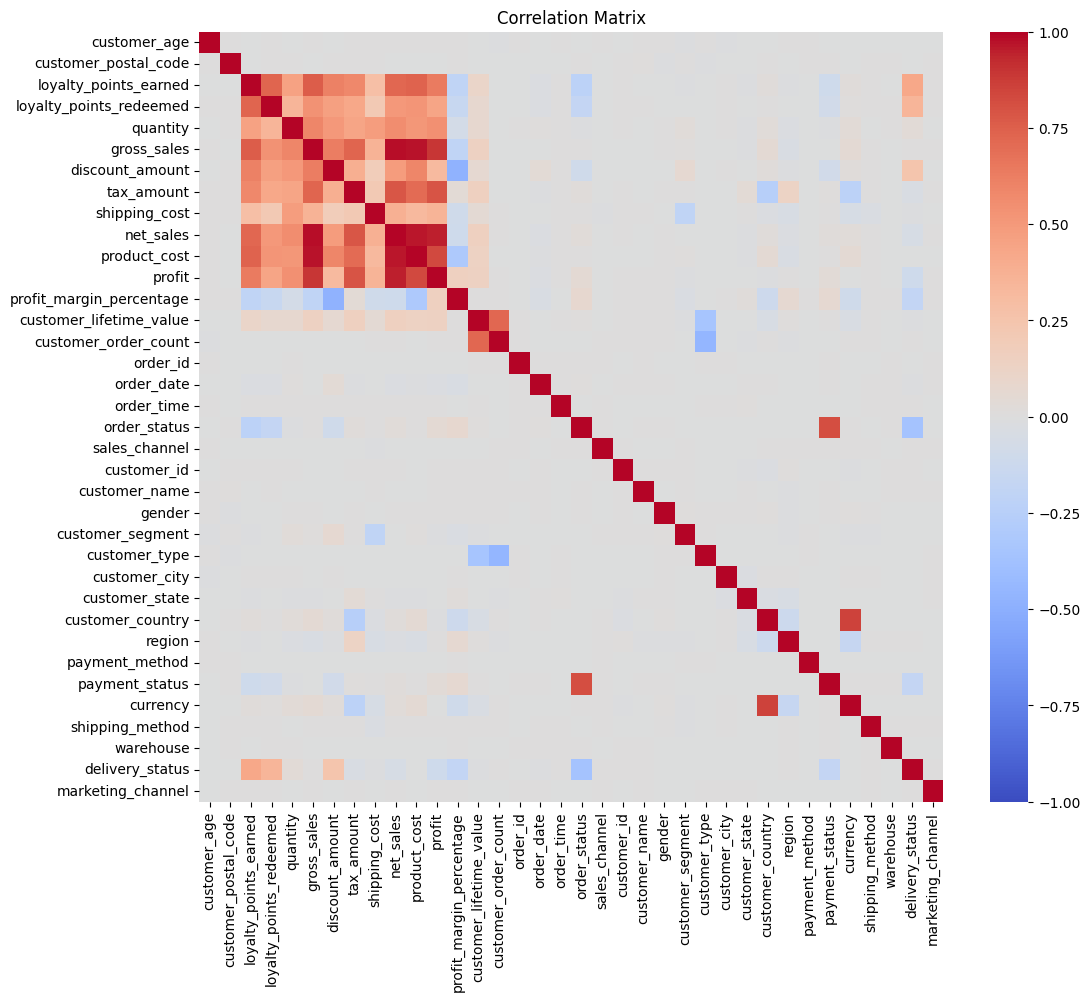

In [10]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

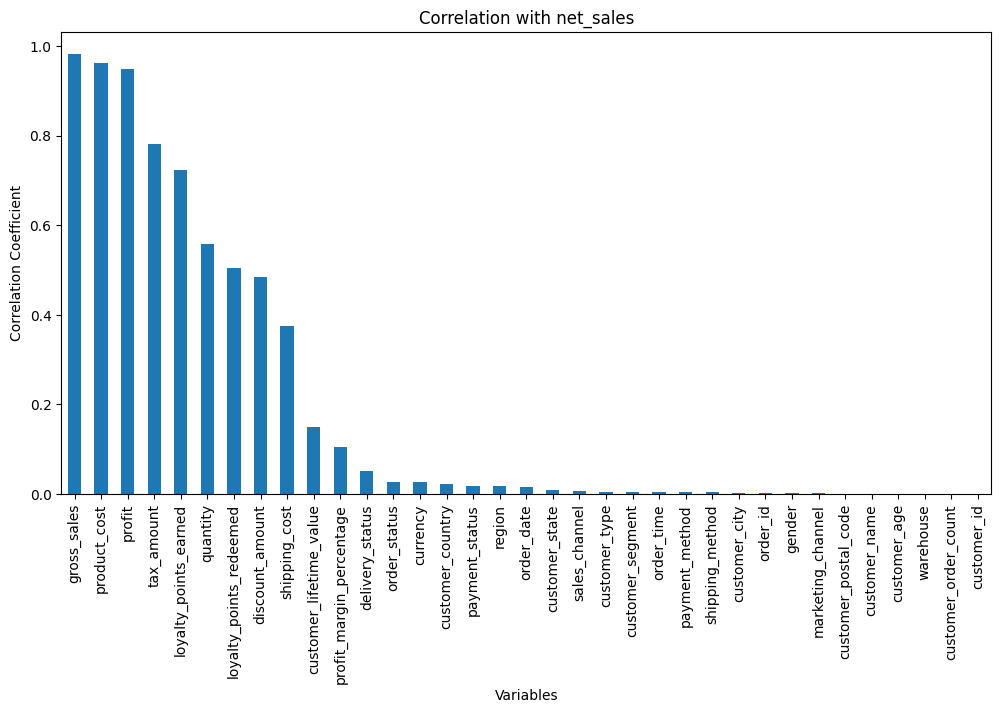

In [11]:
# Menghitung korelasi dengan target 'net_sales' (Menggantikan SalePrice)
target_col = 'net_sales'
if target_col in df_lencoder.columns:
    target_corr = df_lencoder.corr()[target_col]
    
    target_corr_sorted = target_corr.abs().sort_values(ascending=False)
    
    plt.figure(figsize=(12, 6))
    target_corr_sorted.drop(target_col).plot(kind='bar')
    plt.title(f'Correlation with {target_col}')
    plt.xlabel('Variables')
    plt.ylabel('Correlation Coefficient')
    plt.xticks(rotation=90)
    plt.show()

# Data Splitting

In [12]:
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Memisahkan fitur (X) dan target (y)
target_col = 'net_sales'

# Pastikan baris NaN dihapus jika ada residu
df_lencoder = df_lencoder.dropna()

X = df_lencoder.drop(columns=[target_col]) 
y = df_lencoder[target_col]

# Membagi dataset menjadi training dan testing (80:20)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("Jumlah keseluruhan data: ", len(X))
print("Jumlah data latih (Train): ", len(x_train))
print("Jumlah data uji (Test): ", len(x_test))

Jumlah keseluruhan data:  108011
Jumlah data latih (Train):  86408
Jumlah data uji (Test):  21603


# Cross Validation

In [13]:
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

print("\n=== Memulai Cross Validation ===")

# Menggunakan Random Forest dengan jumlah pohon lebih sedikit
model = RandomForestRegressor(
    n_estimators=10,
    max_depth=10,
    random_state=1,
    n_jobs=-1
)

# Menggunakan 5-Fold Cross Validation
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Menjalankan Cross Validation
cv_scores = cross_val_score(
    model,
    x_train,
    y_train,
    cv=kf,
    scoring='r2',
    n_jobs=1
)

# Menampilkan hasil
print("Skor R2 setiap fold:", cv_scores)
print("Rata-rata Skor R2: {:.4f}".format(np.mean(cv_scores)))


=== Memulai Cross Validation ===
Skor R2 setiap fold: [0.999363   0.99934552 0.99943232 0.99936683 0.99935332]
Rata-rata Skor R2: 0.9994
